# Exploring a whole-slide image with TIAToolbox

A whole-slide image holds both the overall tissue structure and the fine detail of individual cells. Here, we use [TIAToolbox](https://github.com/TissueImageAnalytics/tiatoolbox) to move between those scales: opening a slide, selecting tissue patches, adjusting their staining, and segmenting nuclei with HoVer-Net.

The analysis uses a small sample slide to keep processing manageable in Colab. The notebook is configured for a T4 GPU.

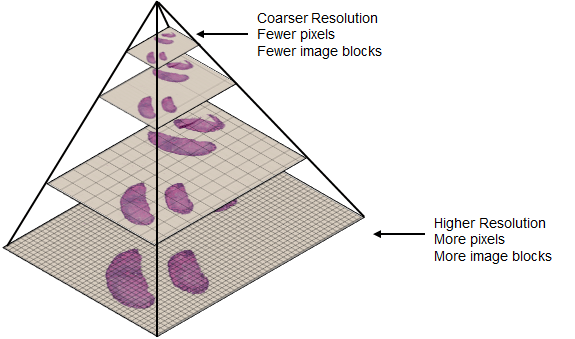

## Preparing the environment

The slide reader needs OpenJPEG and OpenSlide alongside TIAToolbox. The installation below also pins `numcodecs` to the version used in this notebook.

In [ ]:
# Install some system-level required packages
!apt-get -y install libopenjp2-7-dev libopenjp2-tools

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopenjp2-7-dev is already the newest version (2.5.0-2ubuntu0.5).
libopenjp2-tools is already the newest version (2.5.0-2ubuntu0.5).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [ ]:
# Install TIA Toolbox and OpenSlide (it might take a few minutes)
# Need to specify a specific version of numcodecs because of dependency issue
!pip install tiatoolbox openslide-bin numcodecs==0.12.1

## Libraries and plotting helpers

The imports bring together slide reading, patch extraction, stain normalisation, and nuclei analysis. A few plotting helpers make it easier to compare regions and patches throughout the notebook.

In [ ]:
import os
from pathlib import Path
from pprint import pprint

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tiatoolbox.utils.misc import download_data, select_device
from tiatoolbox.utils import imread, imwrite
from tiatoolbox.wsicore.wsireader import WSIReader
from tiatoolbox.tools import patchextraction
from tiatoolbox.tools.stainnorm import MacenkoNormalizer
from tiatoolbox.data import small_svs, stain_norm_target

from tiatoolbox.utils.visualization import overlay_prediction_mask, overlay_prediction_contours

# Reproducibility (within reason)
rng = np.random.default_rng(0)

mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["figure.facecolor"] = "white"
plt.rcParams.update({"font.size": 9})

def show_side_by_side(img1, img2, titles=("A", "B"), figsize=(9, 4)):
    fig, axs = plt.subplots(1, 2, figsize=figsize)
    axs[0].imshow(img1); axs[0].set_title(titles[0]); axs[0].axis("off")
    axs[1].imshow(img2); axs[1].set_title(titles[1]); axs[1].axis("off")
    plt.show()

def show_grid(patches, n=16, title="Patches", figsize=(8, 8)):
    n = min(n, len(patches))
    k = int(np.ceil(np.sqrt(n)))
    fig, axs = plt.subplots(k, k, figsize=figsize)
    fig.suptitle(title)
    axs = np.array(axs).reshape(-1)
    for i in range(k*k):
        axs[i].axis("off")
        if i < n:
            axs[i].imshow(patches[i])
    plt.show()

device = 'cuda'

The sample file contains a 12,000 ? 12,000-pixel slide region, small enough to explore in Colab. The commented alternative uses an even smaller sample when memory or processing time is limited.

In [ ]:
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

# Small WSI
# wsi_small_path = Path(small_svs())
# print("Small WSI:", wsi_small_path, "size(MB)=", wsi_small_path.stat().st_size / 1e6)

# "Moderate" WSI (Colab-friendly)
wsi_med_path = Path(download_data(
    "https://tiatoolbox.dcs.warwick.ac.uk/sample_wsis/wsi4_12k_12k.svs",
    data_dir / "wsi4_12k_12k.svs",
))
print("Moderate WSI:", wsi_med_path, "size(MB)=", wsi_med_path.stat().st_size / 1e6)


Moderate WSI: data/wsi4_12k_12k.svs size(MB)= 18.785787


The `.svs` extension identifies an Aperio whole-slide image. Even this sample contains 144 million pixels, which is why a thumbnail is a more practical starting point than loading the image at full resolution.

## Reading the slide

`WSIReader.open()` gives access to the image and its metadata. The dimensions, resolution levels, and microns-per-pixel values in `info_dict` provide the context needed to read regions at a chosen scale.

In [ ]:
wsi = WSIReader.open(wsi_med_path)

info_dict = wsi.info.as_dict()
pprint(info_dict)

{'axes': 'YXS',
 'file_path': PosixPath('data/wsi4_12k_12k.svs'),
 'level_count': 2,
 'level_dimensions': ((12000, 12000), (3000, 3000)),
 'level_downsamples': [1.0, 4.0],
 'mpp': (np.float64(0.2505), np.float64(0.2505)),
 'objective_power': 40.0,
 'slide_dimensions': (12000, 12000),
 'vendor': 'aperio'}


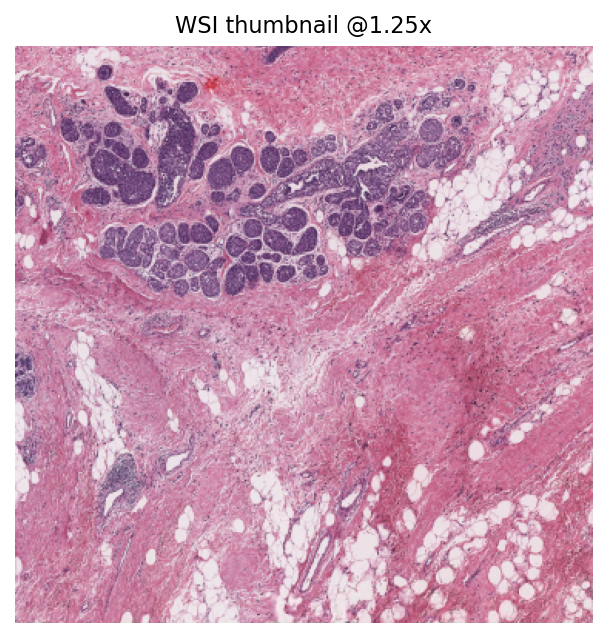

In [ ]:
# the function `slide_thumbnail()` to visualise the WSI image. Notice the different ways
#  to read the image

thumb = wsi.slide_thumbnail(resolution=1.25, units="power")
#thumb = wsi.slide_thumbnail(resolution=0.5, units="mpp") # 0.5 microns per-pixel
#thumb = wsi.slide_thumbnail(resolution=0, units="level") # level 0 at the pyramid layer (highest resolution)
plt.figure(figsize=(6,5))
plt.imshow(thumb)
plt.title("WSI thumbnail @1.25x")
plt.axis("off")
plt.show()

In [ ]:
# Sanity checking the shape of the returned image
# Check this shape every time we run `slide_thumbnail()` with different parameters.
thumb.shape

(375, 375, 3)

Pixel dimensions alone do not describe the physical size of the scanned region. Multiplying the width and height by their respective `mpp` values gives the size in micrometres; dividing by 1,000 converts it to millimetres. These metadata describe the highest-resolution level.

In [ ]:
# Solution, notice mpp and slide_dimensions are for highest resolution
mpp_x, mpp_y = info_dict["mpp"]
w_px, h_px = info_dict["slide_dimensions"] # number of pixels
w_mm = (w_px * mpp_x) / 1000.0
h_mm = (h_px * mpp_y) / 1000.0
print(f"Approx physical size: {w_mm:.2f} mm × {h_mm:.2f} mm")

Approx physical size: 3.01 mm × 3.01 mm


`read_rect()` reads the same starting location at 20? and 5? magnification. Displaying the two regions of interest side by side shows how much tissue context is gained at the lower magnification.

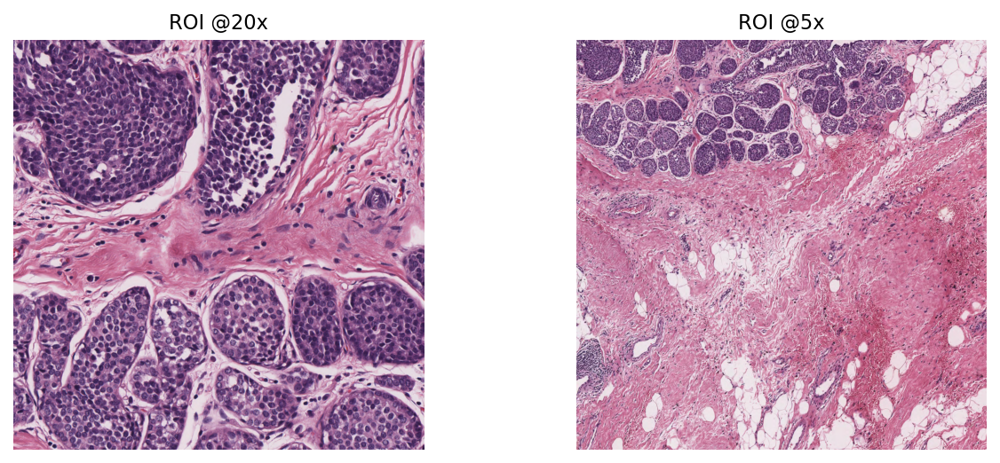

In [ ]:
roi_xy = (2000, 2500)      # top-left (x, y)
roi_size = (1024, 1024)    # (width, height) output size

roi_20x = wsi.read_rect(roi_xy, roi_size, resolution=20, units="power")
roi_5x  = wsi.read_rect(roi_xy, roi_size, resolution=5, units="power")

show_side_by_side(roi_20x, roi_5x, titles=("ROI @20x", "ROI @5x"), figsize=(10,4))

Both views start at `roi_xy = (2000, 2500)` and have the same output dimensions. The 5? image therefore covers a larger physical area, while the 20? image shows finer detail.

A second location gives another view of the tissue. Comparing regions A and B at both magnifications helps reveal differences in nuclear density and tissue structure without assuming that every part of the slide looks alike.

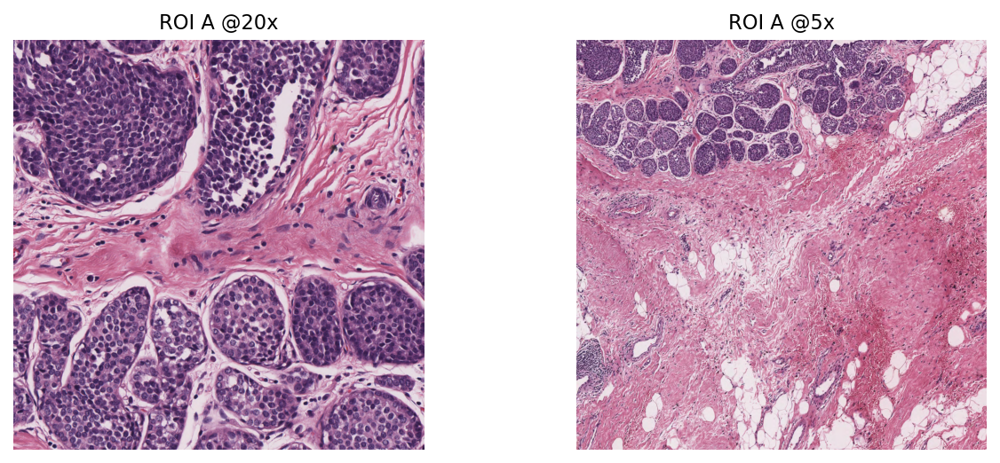

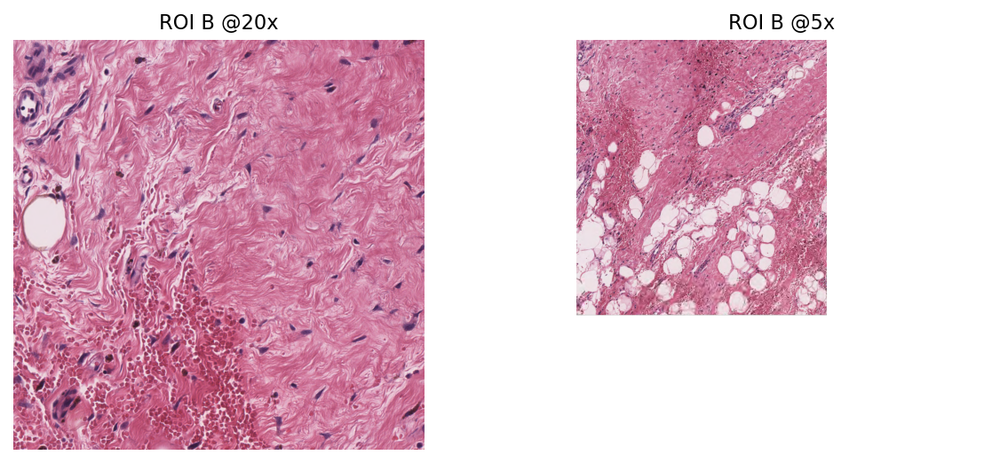

In [ ]:
# Solution
roi_xy_A = (2000, 2500)
roi_xy_B = (7000, 6500)

for name, xy in [("A", roi_xy_A), ("B", roi_xy_B)]:
    a20 = wsi.read_rect(xy, roi_size, resolution=20, units="power")
    a5  = wsi.read_rect(xy, roi_size, resolution=5, units="power")
    show_side_by_side(a20, a5, titles=(f"ROI {name} @20x", f"ROI {name} @5x"), figsize=(10,4))

## Selecting tissue patches

The tissue mask separates likely tissue from the slide background. It guides patch extraction so that the selected images contain tissue rather than mostly empty glass.

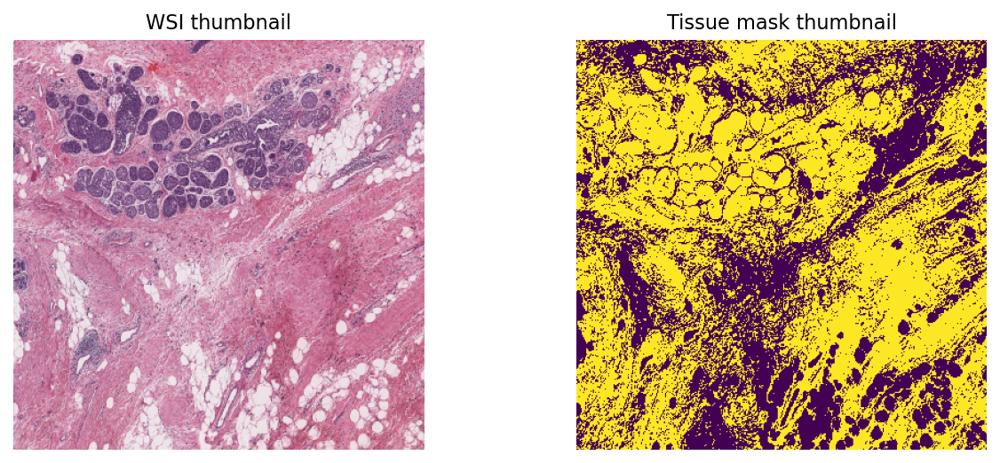

In [ ]:
mask_reader = wsi.tissue_mask(resolution=1.25, units="power")
mask_thumb = mask_reader.slide_thumbnail(resolution=1.25, units="power")

show_side_by_side(thumb, mask_thumb, titles=("WSI thumbnail", "Tissue mask thumbnail"), figsize=(10,4))

The fraction of nonzero pixels in the mask estimates how much of the thumbnail is marked as tissue. This describes the mask coverage at the thumbnail scale.

In [ ]:
if mask_thumb.ndim == 3:
    tissue_frac = (mask_thumb[..., 0] > 0).mean()
else:
    tissue_frac = (mask_thumb > 0).mean()
print(f"Tissue fraction at thumbnail scale: {tissue_frac:.3f}")

Tissue fraction at thumbnail scale: 0.595


The sliding-window extractor produces 224 ? 224-pixel patches using the tissue mask and the chosen stride. The patches are collected in `grid_patches`, and a grid view gives a quick visual check of what was selected.

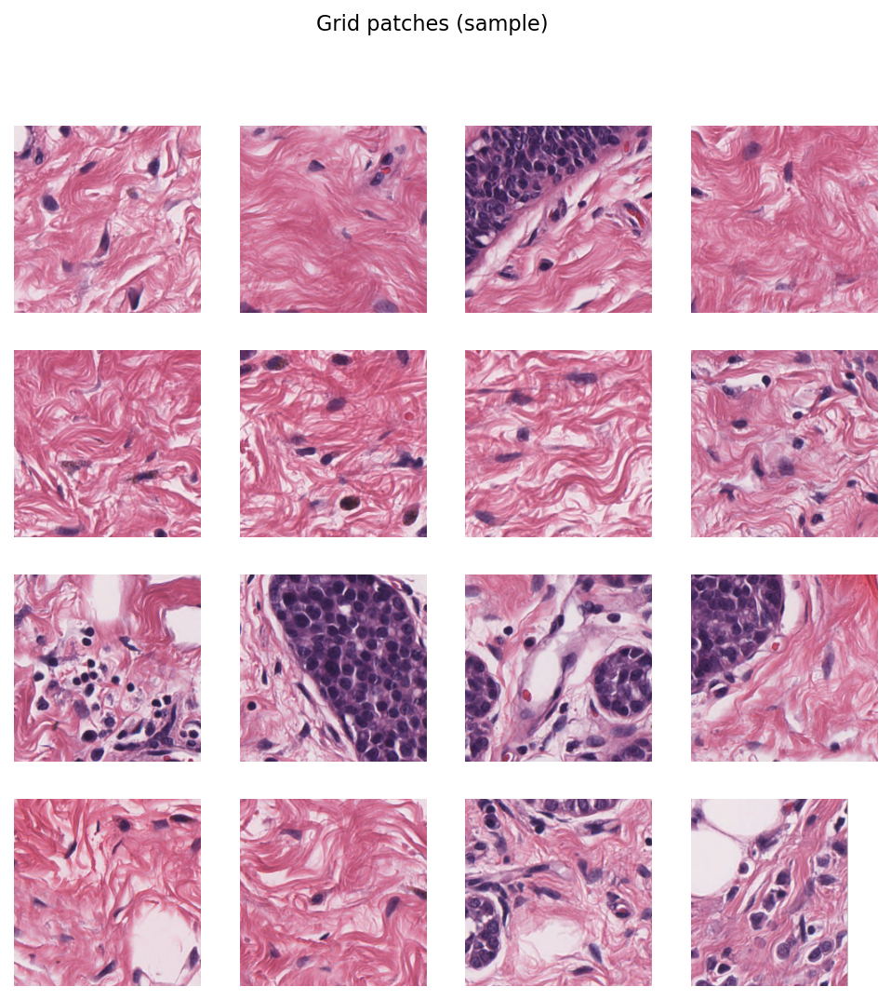

Shown 16 grid patches


In [ ]:
patch_size = (224, 224)
patch_res = 0.5
patch_units = "mpp"
grid_patches = [] # Where we'll save the extracted patches to use later


# GRID extraction (coarse stride to keep runtime reasonable)
grid_stride = (448, 448)
grid_extractor = patchextraction.get_patch_extractor(
    input_img=wsi,
    method_name="slidingwindow",
    patch_size=patch_size,
    stride=grid_stride,
    resolution=patch_res,
    units=patch_units,
    input_mask=mask_reader,
    min_mask_ratio=0.5,
)


for i, p in enumerate(grid_extractor):
    grid_patches.append(p)
    if i >= 15:
        break

show_grid(grid_patches, n=16, title="Grid patches (sample)")
print("Shown", len(grid_patches), "grid patches")

## Bringing stains closer to a reference

Macenko normalisation uses a reference image to adjust the staining of the extracted patches. The reference supplied by TIAToolbox is displayed below before fitting the normaliser.

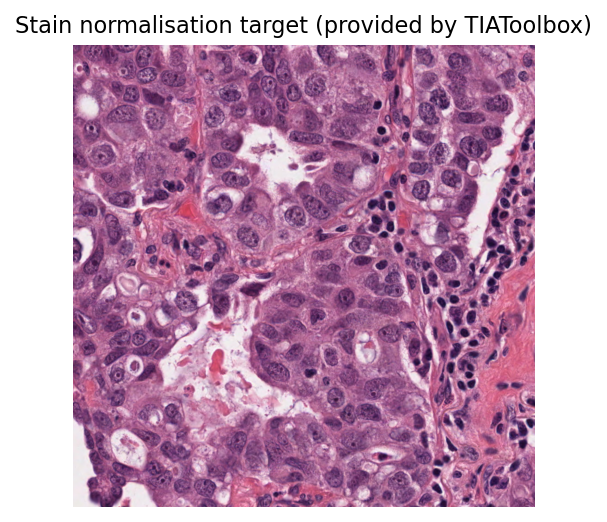

Macenko normaliser fitted.


In [ ]:
target_img = stain_norm_target()
plt.figure(figsize=(4,4))
plt.imshow(target_img)
plt.title("Stain normalisation target (provided by TIAToolbox)")
plt.axis("off")
plt.show()

norm = MacenkoNormalizer()
norm.fit(target_img)
print("Macenko normaliser fitted.")

Four patches are shown before and after normalisation to make the colour changes easy to inspect. If no grid patches are available, the code uses a crop from the 20? region instead.

In [ ]:
norm_patches = [] # Where we'll save the normalised images

src_patches = grid_patches[:4] if len(grid_patches) >= 4 else [roi_20x[:224, :224]]
norm_patches = [norm.transform(p.astype(np.uint8)) for p in src_patches]

for i in range(len(src_patches)):
    show_side_by_side(src_patches[i], norm_patches[i], titles=(f"Before #{i}", f"After #{i}"), figsize=(8,4))

The RGB means and standard deviations add a numerical view of the colour changes. The comparison uses up to ten patches from `grid_patches`, with each patch measured before and after normalisation.

In [ ]:
sample = grid_patches[:10]
rows = []
for i, p in enumerate(sample):
    q = norm.transform(p.astype(np.uint8))
    rows.append({
        "i": i,
        "R_mean_before": p[...,0].mean(), "G_mean_before": p[...,1].mean(), "B_mean_before": p[...,2].mean(),
        "R_std_before":  p[...,0].std(),  "G_std_before":  p[...,1].std(),  "B_std_before":  p[...,2].std(),
        "R_mean_after":  q[...,0].mean(), "G_mean_after":  q[...,1].mean(), "B_mean_after":  q[...,2].mean(),
        "R_std_after":   q[...,0].std(),  "G_std_after":   q[...,1].std(),  "B_std_after":   q[...,2].std(),
    })
df_rgb = pd.DataFrame(rows)
display(df_rgb.head())

,i,R_mean_before,G_mean_before,B_mean_before,R_std_before,G_std_before,B_std_before,R_mean_after,G_mean_after,B_mean_after,R_std_after,G_std_after,B_std_after
0,0,208.809491,142.287089,172.840900,28.768995,38.964458,30.350914,189.262018,121.442104,161.309012,35.524108,42.901195,34.158466
1,1,202.847457,121.831274,157.810627,21.455230,27.081906,22.605617,182.906390,106.555624,149.790298,30.959426,29.794176,25.006962
2,2,170.712392,112.848713,150.924346,55.503400,49.966482,39.590322,171.856027,109.193758,150.721799,56.161344,51.618058,41.668233
3,3,206.136380,124.950773,159.953225,19.577047,28.624717,23.462818,167.696927,95.085360,140.739357,31.861291,32.184224,27.300565
4,4,205.581593,125.466179,158.969228,25.210346,36.853752,29.983549,170.530254,101.521026,145.568917,36.561783,41.246397,33.691699


## Segmenting nuclei with HoVer-Net

The `hovernet_fast-pannuke` model runs through `MultiTaskSegmentor` on a single region extracted from the slide. Its predictions are then overlaid on the tissue image to inspect the detected nuclei. A smaller region reduces processing time when running on a CPU.

In [ ]:
from tiatoolbox.models.engine.multi_task_segmentor import MultiTaskSegmentor
from imageio.v3 import imwrite

roi_for_hover = wsi.read_rect(
    roi_xy,
    (1024, 1024),
    resolution=0.25,
    units="mpp"
)

roi_tile_path = data_dir / "roi_for_hovernet.png"
imwrite(roi_tile_path, roi_for_hover)

segmentor = MultiTaskSegmentor(
    model="hovernet_fast-pannuke",
    num_workers=0,
    batch_size=4,
    device=device,
)

hover_out = segmentor.run(
    [str(roi_tile_path)],
    save_dir=data_dir / "hovernet_roi_result",
    patch_mode=False,
    auto_get_mask=False,
    wsireader_kwargs={"mpp": 0.25},
    overwrite=True,
)

print("HoVer-Net output:", hover_out)

Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(



hovernet_fast-pannuke.pth:   0%|          | 0.00/151M [00:00<?, ?B/s]

Processing WSIs:   0%|          | 0/1 [00:00<?, ?it/s]

Inferring patches:   0%|          | 0/13 [00:00<?, ?it/s]

Merging rows for probability map 0:   0%|          | 0/7 [00:00<?, ?it/s]

Merging rows for probability map 1:   0%|          | 0/7 [00:00<?, ?it/s]

Merging rows for probability map 2:   0%|          | 0/7 [00:00<?, ?it/s]

Generating 'info_dict' for instances:   0%|          | 0/612 [00:00<?, ?it/s]

Saving output to data/hovernet_roi_result/roi_for_hovernet.zarr.:   0%|          | 0/38 [00:00<?, ?it/s]

HoVer-Net output: {PosixPath('data/roi_for_hovernet.png'): PosixPath('data/hovernet_roi_result/roi_for_hovernet.zarr')}


Output keys: ['box', 'centroid', 'contours', 'coordinates', 'prob', 'type']


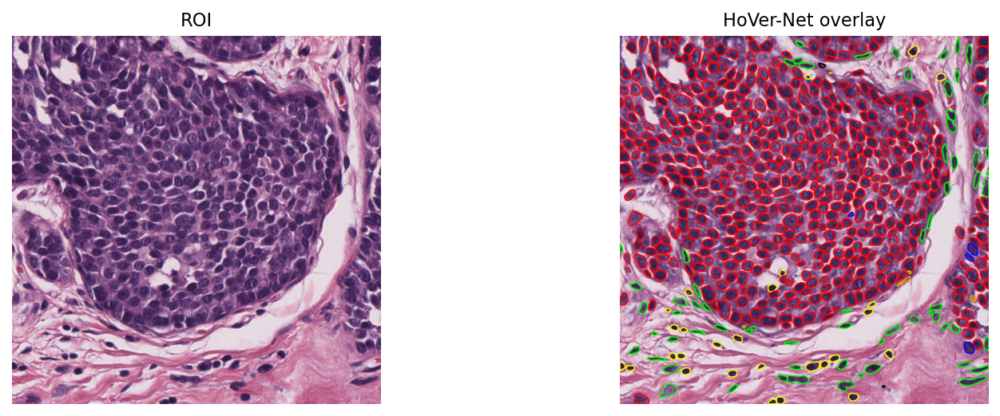

Detected nuclei: 612


In [ ]:
import zarr
from tiatoolbox.utils.visualization import overlay_prediction_contours

# Load HoVer-Net output
zarr_path = hover_out[roi_tile_path]
tile_output = zarr.open(zarr_path, mode="r")

print("Output keys:", list(tile_output.keys()))

# hovernet_fast-pannuke has a single nuclei task,
# so the instance information is stored directly in the Zarr output.
nuclei_instances = tile_output

# Convert to the format expected by overlay_prediction_contours()
tile_preds = {}

for inst_id, (box, centroid, contour, prob, type_id) in enumerate(
    zip(
        nuclei_instances["box"],
        nuclei_instances["centroid"],
        nuclei_instances["contours"],
        nuclei_instances["prob"],
        nuclei_instances["type"],
        strict=False,
    ),
    start=1,
):
    tile_preds[inst_id] = {
        "box": box,
        "centroid": centroid,
        "contour": contour,
        "prob": float(prob),
        "type": int(type_id),
    }

color_dict = {
    0: ("Background", (255, 165, 0)),
    1: ("Neoplastic", (255, 0, 0)),
    2: ("Inflammatory", (255, 255, 0)),
    3: ("Connective", (0, 255, 0)),
    4: ("Dead", (0, 0, 0)),
    5: ("Non-Neoplastic Epithelial", (0, 0, 255)),
}

overlay = overlay_prediction_contours(
    canvas=roi_for_hover,
    inst_dict=tile_preds,
    draw_dot=False,
    type_colours=color_dict,
    line_thickness=2,
)

show_side_by_side(
    roi_for_hover,
    overlay,
    titles=("ROI", "HoVer-Net overlay"),
    figsize=(12, 4),
)

print("Detected nuclei:", len(tile_preds))

The next prediction uses a different slide location. The overlay provides a way to compare the detected nuclei across regions; `line_thickness` and `draw_dot` control how the contours and centres are displayed.

Processing WSIs:   0%|          | 0/1 [00:00<?, ?it/s]

Inferring patches:   0%|          | 0/13 [00:00<?, ?it/s]

Merging rows for probability map 0:   0%|          | 0/7 [00:00<?, ?it/s]

Merging rows for probability map 1:   0%|          | 0/7 [00:00<?, ?it/s]

Merging rows for probability map 2:   0%|          | 0/7 [00:00<?, ?it/s]

Generating 'info_dict' for instances:   0%|          | 0/178 [00:00<?, ?it/s]

Saving output to data/hovernet_roi2_results/roi2_for_hovernet.zarr.:   0%|          | 0/38 [00:00<?, ?it/s]

,count
1,7
2,25
3,136
4,10


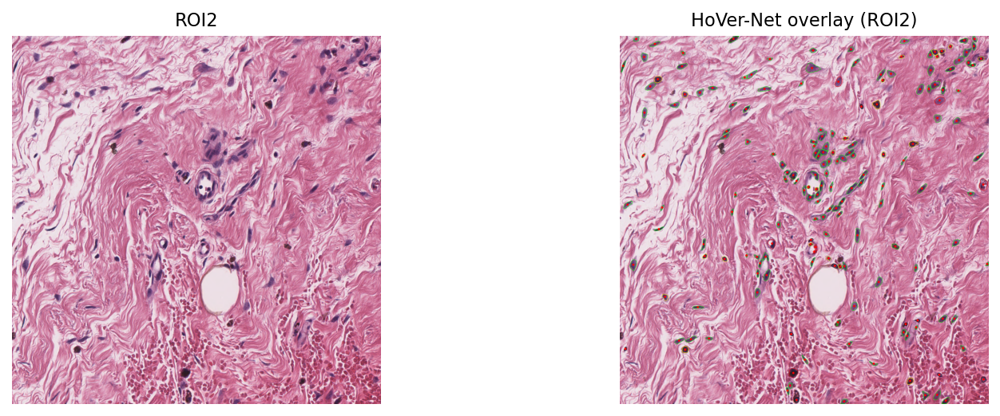

In [ ]:
import zarr
import joblib

roi_xy2 = (6000, 6000)
roi2 = wsi.read_rect(roi_xy2, (1024, 1024), resolution=20, units="power")

roi2_path = data_dir / "roi2_for_hovernet.png"
imwrite(roi2_path, roi2)

# Use the segmentor instance initialized earlier in the notebook
hover_out2 = segmentor.run(
    [str(roi2_path)],
    save_dir=data_dir / "hovernet_roi2_results",
    patch_mode=False,
    auto_get_mask=False,
    wsireader_kwargs={"mpp": 0.25},
    overwrite=True,
)

# Load HoVer-Net output from Zarr
zarr_path2 = hover_out2[roi2_path]
tile_output2 = zarr.open(zarr_path2, mode="r")
nuclei_instances2 = tile_output2

preds2 = {}
for inst_id, (box, centroid, contour, prob, type_id) in enumerate(
    zip(
        nuclei_instances2["box"],
        nuclei_instances2["centroid"],
        nuclei_instances2["contours"],
        nuclei_instances2["prob"],
        nuclei_instances2["type"],
        strict=False,
    ),
    start=1,
):
    preds2[inst_id] = {
        "box": box,
        "centroid": centroid,
        "contour": contour,
        "prob": float(prob),
        "type": int(type_id),
    }

type_ids = [v["type"] for v in preds2.values()]
counts = pd.Series(type_ids).value_counts().sort_index()
display(counts)

overlay2 = overlay_prediction_contours(
    canvas=roi2,
    inst_dict=preds2,
    draw_dot=True,
    type_colours=color_dict,
    line_thickness=1,
)
show_side_by_side(roi2, overlay2, titles=("ROI2", "HoVer-Net overlay (ROI2)"), figsize=(12,4))

## Measuring nuclear shape

The contours stored in `tile_preds` are converted into measurements of area, eccentricity, and equivalent diameter. Area is measured in square pixels and diameter in pixels, so the image resolution matters when comparing these values.

In [ ]:
from skimage.draw import polygon
from skimage.measure import regionprops

def inst_dict_to_features(inst_dict, canvas_shape):
    feats = []
    for nuc_id, nuc in inst_dict.items():
        contour = np.asarray(nuc["contour"], dtype=np.int32)  # (N,2) in x,y
        if contour.ndim != 2 or contour.shape[0] < 3:
            continue

        x, y, w_, h_ = nuc["box"]
        x0, y0 = max(0, x), max(0, y)
        x1, y1 = min(canvas_shape[1], x + w_), min(canvas_shape[0], y + h_)
        if x1 <= x0 or y1 <= y0:
            continue

        cx = contour[:, 0] - x0
        cy = contour[:, 1] - y0
        rr, cc = polygon(cy, cx, shape=(y1 - y0, x1 - x0))
        mask = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
        mask[rr, cc] = 1

        props = regionprops(mask)
        if not props:
            continue
        p = props[0]

        feats.append({
            "nuc_id": nuc_id,
            "type": nuc["type"],
            "area_px2": float(p.area),
            "eccentricity": float(p.eccentricity),
            "equiv_diameter": float(p.equivalent_diameter),
            "centroid_x": float(nuc["centroid"][0]),
            "centroid_y": float(nuc["centroid"][1]),
        })
    return pd.DataFrame(feats)

df_feat = inst_dict_to_features(tile_preds, roi_for_hover.shape[:2])
display(df_feat.head())
print("Nuclei with features:", len(df_feat), "/", len(tile_preds))

,nuc_id,type,area_px2,eccentricity,equiv_diameter,centroid_x,centroid_y
0,1,1,811.0,0.877664,32.134052,64.515413,20.368681
1,2,1,261.0,0.491193,18.229523,160.053640,7.386973
2,3,1,148.0,0.738652,13.727325,361.344595,6.344595
3,4,1,542.0,0.629552,26.269675,569.678967,11.313653
4,5,1,428.0,0.753059,23.344090,621.637850,7.789720


Nuclei with features: 612 / 612


HoVer-Net is also run on a stain-normalised version of the original region. Comparing the shape measurements and their distributions shows whether the predictions change after the colour adjustment. These differences reflect the segmentation results, rather than a physical change in the tissue.

In [ ]:
import zarr

roi_norm = norm.transform(roi_for_hover.astype(np.uint8))
roi_norm_path = data_dir / "roi_for_hovernet_norm.png"
imwrite(roi_norm_path, roi_norm)

# Corrected to use 'segmentor' and '.run()'
hover_out_norm = segmentor.run(
    [str(roi_norm_path)],
    save_dir=data_dir / "hovernet_roi_norm_results",
    patch_mode=False,
    auto_get_mask=False,
    wsireader_kwargs={"mpp": 0.25},
    overwrite=True,
)

# Load HoVer-Net output from Zarr
zarr_path_norm = hover_out_norm[roi_norm_path]
tile_output_norm = zarr.open(zarr_path_norm, mode="r")
nuclei_instances_norm = tile_output_norm

preds_norm = {}
for inst_id, (box, centroid, contour, prob, type_id) in enumerate(
    zip(
        nuclei_instances_norm["box"],
        nuclei_instances_norm["centroid"],
        nuclei_instances_norm["contours"],
        nuclei_instances_norm["prob"],
        nuclei_instances_norm["type"],
        strict=False,
    ),
    start=1,
):
    preds_norm[inst_id] = {
        "box": box,
        "centroid": centroid,
        "contour": contour,
        "prob": float(prob),
        "type": int(type_id),
    }

df_feat_norm = inst_dict_to_features(preds_norm, roi_norm.shape[:2])
print("Original feats:", len(df_feat), " Normalised feats:", len(df_feat_norm))

Processing WSIs:   0%|          | 0/1 [00:00<?, ?it/s]

Inferring patches:   0%|          | 0/13 [00:00<?, ?it/s]

Merging rows for probability map 0:   0%|          | 0/7 [00:00<?, ?it/s]

Merging rows for probability map 1:   0%|          | 0/7 [00:00<?, ?it/s]

Merging rows for probability map 2:   0%|          | 0/7 [00:00<?, ?it/s]

Generating 'info_dict' for instances:   0%|          | 0/599 [00:00<?, ?it/s]

Saving output to data/hovernet_roi_norm_results/roi_for_hovernet_norm.zarr.:   0%|          | 0/38 [00:00<?, ?…

Original feats: 612  Normalised feats: 599


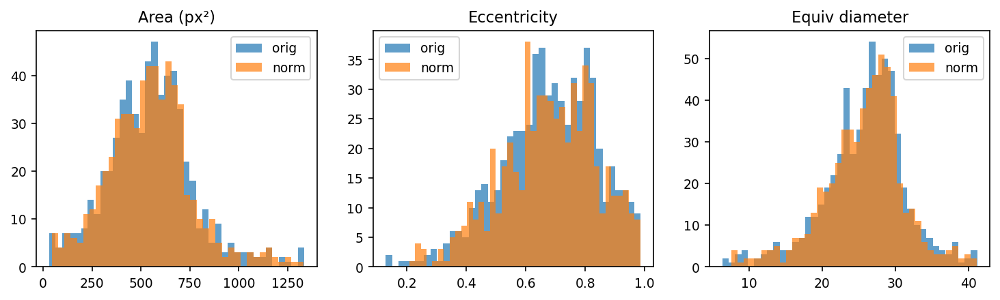

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))

axs[0].hist(df_feat["area_px2"], bins=40, alpha=0.7, label="orig")
axs[0].hist(df_feat_norm["area_px2"], bins=40, alpha=0.7, label="norm")
axs[0].set_title("Area (px²)"); axs[0].legend()

axs[1].hist(df_feat["eccentricity"], bins=40, alpha=0.7, label="orig")
axs[1].hist(df_feat_norm["eccentricity"], bins=40, alpha=0.7, label="norm")
axs[1].set_title("Eccentricity"); axs[1].legend()

axs[2].hist(df_feat["equiv_diameter"], bins=40, alpha=0.7, label="orig")
axs[2].hist(df_feat_norm["equiv_diameter"], bins=40, alpha=0.7, label="norm")
axs[2].set_title("Equiv diameter"); axs[2].legend()

plt.show()

In [ ]:
def summarise(df):
    return df.groupby("type")[["area_px2", "eccentricity", "equiv_diameter"]].agg(["mean", "std", "count"])

display(summarise(df_feat))
display(summarise(df_feat_norm))

area_px2                   eccentricity                  \
            mean         std count         mean       std count   
type                                                              
0      99.600000   84.120747     5     0.858909  0.110623     5   
1     580.629191  203.575734   507     0.648375  0.149481   507   
2     357.444444  145.758582    27     0.690624  0.099309    27   
3     442.656716  245.110832    67     0.882565  0.088854    67   
4     104.000000  101.823376     2     0.772046  0.064484     2   
5     453.250000  283.713911     4     0.766277  0.115847     4   

     equiv_diameter                  
               mean       std count  
type                                 
0         10.533659  4.452061     5  
1         26.739070  4.934592   507  
2         20.926784  4.224092    27  
3         22.850373  6.488206    67  
4         10.676359  6.071618     2  
5         22.927147  8.281847     4

area_px2                   eccentricity                  \
            mean         std count         mean       std count   
type                                                              
1     574.373757  199.324146   503     0.649596  0.148102   503   
2     356.625000  123.139656    24     0.691060  0.087255    24   
3     415.391304  254.465138    69     0.875978  0.092445    69   
4     213.500000   19.091883     2     0.846345  0.054450     2   
5     305.000000         NaN     1     0.878188       NaN     1   

     equiv_diameter                  
               mean       std count  
type                                 
1         26.605046  4.851152   503  
2         20.971828  3.856306    24  
3         21.884348  7.120588    69  
4         16.479219  0.737551     2  
5         19.706295       NaN     1